In [1]:
%load_ext autoreload
%autoreload 2
import os

#import cordex as cx
import geopandas as gpd
#from cartopy import crs as ccrs
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from shapely.geometry import Polygon
import xesmf as xe

from pathlib import Path

In [2]:
from pyproj import CRS

CRS.from_epsg(4326)


<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [3]:
wkd = os.getcwd()
wkd

'/home/g/g300047/SCRIPTS/github/udag'

In [ ]:
!ls eva-suite/


In [40]:
shapefile =os.path.join(wkd, "/eva-suite/UDAG_EvaSuite_allpolygones_regiklim_msf_200226.gpkg")

In [41]:
shapefile

'/eva-suite/UDAG_EvaSuite_allpolygones_regiklim_msf_200226.gpkg'

In [42]:
gdf = gpd.read_file(wkd+shapefile)
gdf.head()

,id_9,id_8,NAME_0,id_6,id,id_0,id_1,id_2,id_3,id_4,id_5,id_7,geometry
0,1,NaN,IAWAK-EE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((13.16349 51.75487, 13.16345 51..."
1,2,NaN,klimakonform,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((11.44677 51.1945, 11.44538 51...."
2,3,NaN,WAKOS_Festland,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((6.86501 53.5911, 6.86554 53.59..."
3,4,NaN,KARE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((11.43016 47.98022, 11.43071 47..."
4,5,NaN,ISAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((9.16875 48.60398, 9.16961 48.6..."


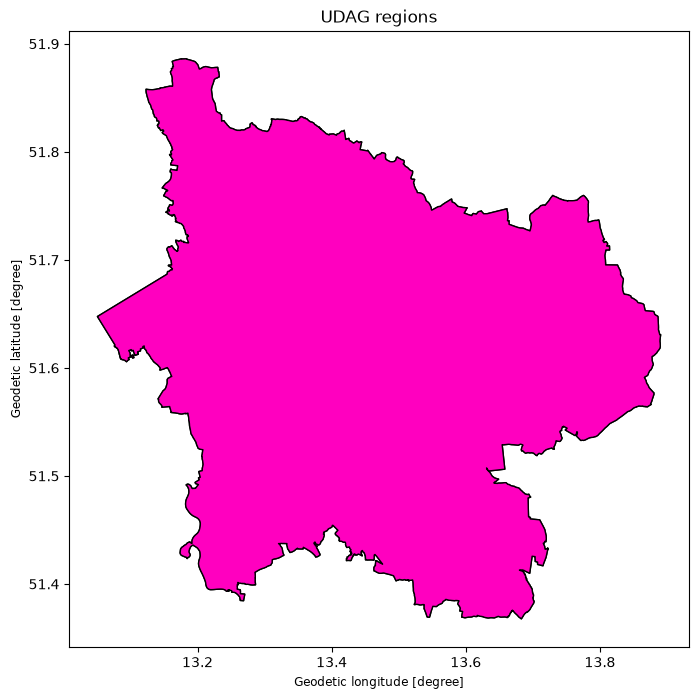

In [43]:
regions = [
    #"Germany",
    #"KARE",
    #"Duisburg_3x3",
    #"klimakonform",
    "IAWAK-EE",
    #"WAKOS_Festland",
    #"ISAP"
]
#regions = ["Germany", "IAWAK-EE","WAKOS_Festland"]
gdf_sel = gdf[gdf["NAME_0"].isin(regions)]

fig, ax = plt.subplots(figsize=(8, 8))

gdf_sel.plot(
    ax=ax,
    edgecolor="black",
    cmap="gist_rainbow"
)
ax.set_title("UDAG regions")
plt.show()

In [22]:
# make nice
#drp columns not needed
#gdf_sel = gdf_sel.drop(columns=["id", "id_0","id_1", "id_2", "id_3", "id_4", "id_5","id_6", "id_7", "id_8", "id_9"])


In [44]:
# rename columns for clarity
gdf_sel = gdf_sel.rename(columns={
    "NAME_0": "region"
})  

In [45]:
gdf_sel

,id_9,id_8,region,id_6,id,id_0,id_1,id_2,id_3,id_4,id_5,id_7,geometry
0,1,NaN,IAWAK-EE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((13.16349 51.75487, 13.16345 51..."
651,NaN,NaN,IAWAK-EE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((13.16349 51.75487, 13.16345 51..."


In [46]:
# now save
gdf_sel.to_file(wkd+"/Udag_regions_part2.shp")

In [12]:
# with poly.is_valid   check
gdf_sel["is_valid"] = gdf_sel["geometry"].apply(lambda x: x.is_valid)
gdf_sel[["region", "is_valid"]]
print(gdf_sel[["region", "is_valid"]])

# check if any invalid geometries exist
gdf_sel[~gdf_sel["is_valid"]]
# optionally, fix invalid geometries
gdf_sel["geometry"] = gdf_sel["geometry"].apply(lambda x: x.buffer(0) if not x.is_valid else x)
# recheck validity after fixing
gdf_sel["is_valid"] = gdf_sel["geometry"].apply(lambda x: x.is_valid)
gdf_sel[["region", "is_valid"]]
# save the fixed shapefile
gdf_sel.to_file(wkd+"/Udag_regions_clean_fixed.shp")


             region  is_valid
0          IAWAK-EE      True
1      klimakonform      True
2    WAKOS_Festland      True
3              KARE      True
4              ISAP      True
5      Duisburg_3x3      True
591         Germany      True
651        IAWAK-EE      True
656            KARE      True
657            ISAP      True
659  WAKOS_Festland      True
662    Duisburg_3x3      True


In [27]:
import geopandas as gpd

gdf = gpd.read_file(wkd + "/Udag_regions_fresh.shp")

print("CRS:", gdf.crs)
print("Geometry types:\n", gdf.geom_type.value_counts())
print("Invalid:", (~gdf.geometry.is_valid).sum())
print("Empty:", gdf.geometry.is_empty.sum())
print("Missing:", gdf.geometry.isna().sum())

CRS: EPSG:4326
Geometry types:
 Polygon         6
MultiPolygon    6
Name: count, dtype: int64
Invalid: 0
Empty: 0
Missing: 0


xESMF expects polygon coordinates in longitude/latitude. If the shapefile has a known CRS other than EPSG:4326, reproject it (don’t just assign a CRS):

gdf = gdf.to_crs("EPSG:4326")


In [28]:
from shapely.validation import explain_validity

gdf = gpd.read_file(wkd + "/Udag_regions_fresh.shp")



invalid = gdf.geometry.notna() & ~gdf.geometry.is_valid

if invalid.any():
    print(f"{invalid.sum()} geometries need repair:")
    for idx, row in gdf.loc[invalid].iterrows():
        print(
            f"Index {idx}, region={row.get('region', '<unknown>')}: "
            f"{explain_validity(row.geometry)}"
        )
else:
    print("No invalid geometries found.")

No invalid geometries found.


In [54]:
from shapely import make_valid
from shapely.geometry import Polygon, MultiPolygon, GeometryCollection
from shapely.ops import unary_union

gdf = gpd.read_file(wkd + "/Udag_regions_clean_fixed.shp")

def repair_polygonal(geom):
    if geom is None or geom.is_empty:
        return None

    def polygon_parts(g):
        if isinstance(g, Polygon):
            yield g
        elif isinstance(g, (MultiPolygon, GeometryCollection)):
            for part in g.geoms:
                yield from polygon_parts(part)

    parts = list(polygon_parts(make_valid(geom)))
    return unary_union(parts) if parts else None

gdf["geometry"] = gdf.geometry.apply(repair_polygonal)
gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty].copy()

print("Invalid after repair:", (~gdf.geometry.is_valid).sum())
print("Types after repair:\n", gdf.geom_type.value_counts())

Invalid after repair: 0
Types after repair:
 Polygon         6
MultiPolygon    6
Name: count, dtype: int64


In [47]:
gdf_xw = gpd.read_file(wkd + "/Udag_regions_part2.shp")

In [49]:
# EPSG:3035 verwendet Meter und eignet sich für diese Region.
gdf_fixed = gdf_xw.to_crs("EPSG:3035")

mask = gdf_fixed["region"].eq("IAWAK-EE")
gdf_fixed.loc[mask, "geometry"] = (
    gdf_fixed.loc[mask, "geometry"]
    .simplify(tolerance=0.1, preserve_topology=True)
)

# xESMF benötigt Längen- und Breitengrade.
gdf_fixed = gdf_fixed.to_crs("EPSG:4326")

In [53]:
from xesmf.backend import Mesh
from xesmf.util import split_polygons_and_holes

if gdf_all.crs is None:
    raise ValueError("Identify the original CRS before reprojecting.")

gdf_test = gdf_all.to_crs("EPSG:4326")

for idx, row in gdf_test.iterrows():
    try:
        exteriors, holes, _, _ = split_polygons_and_holes([row.geometry])
        mesh = Mesh.from_polygons(exteriors)
    except Exception as exc:
        print(f"FAILED: index={idx}, region={row['region']}")
        print(f"{type(exc).__name__}: {exc}")
        if exc.__cause__ is not None:
            print("Underlying error:", repr(exc.__cause__))
    else:
        print(f"OK: index={idx}, region={row['region']}")
        mesh.destroy()

OK: index=0, region=IAWAK-EE
OK: index=1, region=IAWAK-EE
OK: index=2, region=klimakonform
OK: index=3, region=WAKOS_Festland
OK: index=4, region=KARE
OK: index=5, region=ISAP
OK: index=6, region=Duisburg_3x3
OK: index=7, region=Germany
OK: index=8, region=KARE
OK: index=9, region=ISAP
OK: index=10, region=WAKOS_Festland
OK: index=11, region=Duisburg_3x3


In [52]:
gdf_xw = gpd.read_file(wkd + "/Udag_regions_part.shp")
#con cat gdf_xw to gdf_fixed
gdf_all = pd.concat([gdf_fixed, gdf_xw], ignore_index=True)
gdf_all.to_file(wkd + "/Udag_regions_all_fresh.shp")
gdf_all


,id_9,id_8,region,id_6,id,id_0,id_1,id_2,id_3,id_4,id_5,id_7,geometry
0,1,NaN,IAWAK-EE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((13.16349 51.75487, 13.16088 51.75481..."
1,NaN,NaN,IAWAK-EE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((13.16349 51.75487, 13.16088 51.75481..."
2,2,NaN,klimakonform,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((11.44677 51.1945, 11.44538 51...."
3,3,NaN,WAKOS_Festland,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((6.86501 53.5911, 6.86554 53.59..."
4,4,NaN,KARE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((11.43016 47.98022, 11.43071 47.97905..."
5,5,NaN,ISAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((9.16875 48.60398, 9.16961 48.6..."
6,6,NaN,Duisburg_3x3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((6.46907 51.17857, 6.38699 51.50455, ..."
7,NaN,NaN,Germany,NaN,NaN,86.0,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((8.66879 47.69019, 8.66709 47.6..."
8,NaN,NaN,KARE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"POLYGON ((11.43016 47.98022, 11.43071 47.97905..."
9,NaN,NaN,ISAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((9.16875 48.60398, 9.16961 48.6..."


In [17]:
gdf_test

,id_9,id_8,region,id_6,id,id_0,id_1,id_2,id_3,id_4,id_5,id_7,is_valid,geometry
0,1,NaN,IAWAK-EE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"POLYGON ((13.16349 51.75487, 13.16345 51.75487..."
1,2,NaN,klimakonform,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"MULTIPOLYGON (((11.44677 51.1945, 11.44538 51...."
2,3,NaN,WAKOS_Festland,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"MULTIPOLYGON (((6.86501 53.5911, 6.86554 53.59..."
3,4,NaN,KARE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"POLYGON ((11.43016 47.98022, 11.43071 47.97905..."
4,5,NaN,ISAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"MULTIPOLYGON (((9.16875 48.60398, 9.16961 48.6..."
5,6,NaN,Duisburg_3x3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"POLYGON ((6.46907 51.17857, 6.38699 51.50455, ..."
6,NaN,NaN,Germany,NaN,NaN,86.0,NaN,NaN,NaN,NaN,NaN,NaN,True,"MULTIPOLYGON (((8.66879 47.69019, 8.66709 47.6..."
7,NaN,NaN,IAWAK-EE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"POLYGON ((13.16349 51.75487, 13.16345 51.75487..."
8,NaN,NaN,KARE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"POLYGON ((11.43016 47.98022, 11.43071 47.97905..."
9,NaN,NaN,ISAP,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,"MULTIPOLYGON (((9.16875 48.60398, 9.16961 48.6..."


In [16]:
gdf_xw = gpd.read_file(wkd + "/Udag_regions_clean_fixed.shp")

print("CRS:", gdf_xw.crs)
print("Geometry types:\n", gdf_xw.geom_type.value_counts())
print("Repeated regions:\n", gdf_xw["region"].value_counts()[lambda s: s > 1])

if gdf_xw.crs is None:
    raise ValueError("The shapefile has no CRS. Set it only after confirming its source CRS.")

# Use the grid's CRS here; EPSG:4326 is typical for lon/lat grids.
gdf_xw = gdf_xw.to_crs("EPSG:4326")

# Combine duplicate records into one geometry per region.
gdf_xw = gdf_xw.dissolve(by="region", as_index=False)
gdf_xw = gdf_xw[gdf_xw.geometry.notna() & ~gdf_xw.geometry.is_empty].copy()

print("Invalid geometries:", (~gdf_xw.geometry.is_valid).sum())
print("Regions:", gdf_xw["region"].tolist())

CRS: EPSG:4326
Geometry types:
 Polygon         6
MultiPolygon    6
Name: count, dtype: int64
Repeated regions:
 region
IAWAK-EE          2
WAKOS_Festland    2
KARE              2
ISAP              2
Duisburg_3x3      2
Name: count, dtype: int64
Invalid geometries: 0
Regions: ['Duisburg_3x3', 'Germany', 'IAWAK-EE', 'ISAP', 'KARE', 'WAKOS_Festland', 'klimakonform']


In [64]:
# Index öffnen
index_dir='/work/ch0636/g300047/UDAG/index_calculation/cordex/HYR-5/GERICS/DWD/MPI-M-MPI-ESM-LR/historical/r1i1p1/MPI-CSC-REMO2009/v1/year/TG/xcalc_1000-dev737+gef63188c3'
file_index =os.path.join(index_dir,'TG_HYR-5_MPI-M-MPI-ESM-LR_historical_r1i1p1_MPI-CSC-REMO2009_v1_day_GERICS_year_1951-1951.nc')
print(file_index)
ds=xr.open_dataset(file_index, decode_timedelta=False)
ds.lat.values

/work/ch0636/g300047/UDAG/index_calculation/cordex/HYR-5/GERICS/DWD/MPI-M-MPI-ESM-LR/historical/r1i1p1/MPI-CSC-REMO2009/v1/year/TG/xcalc_1000-dev737+gef63188c3/TG_HYR-5_MPI-M-MPI-ESM-LR_historical_r1i1p1_MPI-CSC-REMO2009_v1_day_GERICS_year_1951-1951.nc


array([[55.43871656, 55.44378067, 55.44879418, ..., 55.20897472,
        55.20195241, 55.19488031],
       [55.39263969, 55.39769863, 55.40270702, ..., 55.16313135,
        55.15611614, 55.14905119],
       [55.34655874, 55.35161252, 55.35661581, ..., 55.11728356,
        55.11027545, 55.10321765],
       ...,
       [45.39977619, 45.40386872, 45.40792025, ..., 45.21399204,
        45.20830966, 45.20258679],
       [45.3535718 , 45.35766043, 45.3617081 , ..., 45.16796401,
        45.16228702, 45.15656956],
       [45.30737008, 45.31145482, 45.31549864, ..., 45.12193847,
        45.11626685, 45.11055481]], shape=(220, 240))

In [65]:


#ds = your_climate_dataset  # Your existing xarray Dataset or DataArray

for idx, row in gdf_xw.iterrows():
    try:
        averager = xe.SpatialAverager(ds, [row.geometry])
    except Exception as exc:
        print(f"FAILED: index={idx}, region={row['region']}")
        print(f"{type(exc).__name__}: {exc}")
    else:
        print(f"OK: index={idx}, region={row['region']}")

FAILED: index=0, region=Duisburg_3x3
KeyError: 'lon_b'
FAILED: index=1, region=Germany
KeyError: 'lon_b'
FAILED: index=2, region=IAWAK-EE
KeyError: 'lon_b'
FAILED: index=3, region=ISAP
KeyError: 'lon_b'
FAILED: index=4, region=KARE
KeyError: 'lon_b'
FAILED: index=5, region=WAKOS_Festland
KeyError: 'lon_b'
FAILED: index=6, region=klimakonform
KeyError: 'lon_b'


In [67]:
print(type(ds))
print(ds)

<class 'xarray.core.dataset.Dataset'>
<xarray.Dataset> Size: 1MB
Dimensions:    (time: 1, y: 220, x: 240, bnds: 2)
Coordinates:
  * time       (time) datetime64[ns] 8B 1951-07-02T12:00:00
  * y          (y) float64 2kB 3.198e+06 3.192e+06 ... 2.108e+06 2.102e+06
  * x          (x) float64 2kB 3.502e+06 3.508e+06 ... 4.692e+06 4.698e+06
    lat        (y, x) float64 422kB 55.44 55.44 55.45 ... 45.12 45.12 45.11
    lon        (y, x) float64 422kB 1.871 1.952 2.033 ... 19.03 19.09 19.16
Dimensions without coordinates: bnds
Data variables:
    crs        int32 4B ...
    TG         (time, y, x) float32 211kB ...
    time_bnds  (time, bnds) datetime64[ns] 16B ...
Attributes: (12/62)
    title:                          bias-adjusted and interpolated RCM (TAS)
    source:                         CORDEX - RCM projection run, surface obse...
    institution:                    Department Climate and Environment Consul...
    project_id:                     BMDV-ExpN-SP101
    contact:         

In [62]:
import xesmf as xe

for idx, row in gdf_xw.iterrows():
    try:
        averager = xe.SpatialAverager(ds, [row.geometry])
    except Exception as exc:
        print(f"FAILED: index={idx}, region={row['region']}")
        print(f"{type(exc).__name__}: {exc}")
    else:
        print(f"OK: index={idx}, region={row['region']}")

FAILED: index=0, region=Duisburg_3x3
NameError: name 'ds' is not defined
FAILED: index=1, region=Germany
NameError: name 'ds' is not defined
FAILED: index=2, region=IAWAK-EE
NameError: name 'ds' is not defined
FAILED: index=3, region=ISAP
NameError: name 'ds' is not defined
FAILED: index=4, region=KARE
NameError: name 'ds' is not defined
FAILED: index=5, region=WAKOS_Festland
NameError: name 'ds' is not defined
FAILED: index=6, region=klimakonform
NameError: name 'ds' is not defined


In [37]:
gdf_xw

,region,geometry,is_valid
0,Duisburg_3x3,"POLYGON ((6.38699 51.50455, 6.9111 51.55485, 6...",True
1,Germany,"MULTIPOLYGON (((6.76694 53.61792, 6.76694 53.6...",True
2,IAWAK-EE,"POLYGON ((13.16345 51.75487, 13.16335 51.75487...",True
3,ISAP,"MULTIPOLYGON (((9.17108 48.60399, 9.17108 48.6...",True
4,KARE,"POLYGON ((11.43071 47.97905, 11.43273 47.97913...",True
5,WAKOS_Festland,"MULTIPOLYGON (((7.80963 53.70697, 7.8099 53.70...",True
6,klimakonform,"MULTIPOLYGON (((11.62094 51.31574, 11.62317 51...",True


In [57]:
print("nuts:", nuts.crs, nuts.shape)
print("gdf_xw:", gdf_xw.crs, gdf_xw.shape)

nuts: EPSG:4326 (511, 6)
gdf_xw: EPSG:4326 (7, 14)


In [58]:
print("CRS:", gdf_xw.crs)
print("Bounds:", gdf_xw.total_bounds)
print("Types:\n", gdf_xw.geom_type.value_counts())
print("Missing:", gdf_xw.geometry.isna().sum())
print("Empty:", gdf_xw.geometry.is_empty.sum())
print("Invalid:", (~gdf_xw.geometry.is_valid).sum())

if gdf_xw.crs is None:
    raise ValueError("Identify the original CRS before reprojecting.")

gdf_xw = gdf_xw.to_crs("EPSG:4326")

CRS: EPSG:4326
Bounds: [ 5.87161922 47.26985931 15.03811264 55.05652618]
Types:
 MultiPolygon    4
Polygon         3
Name: count, dtype: int64
Missing: 0
Empty: 0
Invalid: 0


In [ ]:
shape_dir = os.path.join(wkd,'Shapefiles_Nukleus')
shapefiles = [f for f in os.listdir(shape_dir) if f.endswith('.shp')]
for shapefile in shapefiles:
    shapefile_path = os.path.join(shape_dir, shapefile)
    gdf = gpd.read_file(shapefile_path)
    print(gdf.head())
    print(shapefile)

In [ ]:
test = shapefiles[3]
print(test)
gdf=gpd.read_file(os.path.join(shape_dir, test))
print(gdf.head())
gdf.plot(figsize=(8, 8))

In [ ]:
print(gdf.crs)

In [ ]:
gdf_ll = gdf.to_crs("EPSG:4326")

In [ ]:
gdf_ll.to_file(os.path.join(shape_dir,"KARE_latlon.shp"))


In [ ]:
gdf_test=gpd.read_file(os.path.join(shape_dir, "KARE_latlon.shp"))
gdf_test.plot()

In [ ]:
shape_dir = os.path.join(wkd,'Shapefiles_Nukleus')
new_dir = os.path.join(wkd,'New_Shapefiles_Nukleus')
shapefiles = [f for f in os.listdir(shape_dir) if f.endswith('.shp')]
for shapefile in shapefiles:
    shapefile_path = os.path.join(shape_dir, shapefile)
    gdf = gpd.read_file(shapefile_path)
    outfile = shapefile.replace(".shp", "_latlon.shp")
    gdf_ll = gdf.to_crs("EPSG:4326")
    new_shapefile_path = os.path.join(new_dir, outfile)
    gdf_ll.to_file(new_shapefile_path)
    print(shapefile)



In [ ]:

shape_dir = os.path.join(wkd,'Shapefiles_Nukleus')
new_dir = os.path.join(wkd,'New_Shapefiles_Nukleus')
shapefiles = [f for f in os.listdir(shape_dir) if f.endswith('.shp')]
gdfs = []

for shapefile in shapefiles:
    shapefile_path = os.path.join(shape_dir, shapefile)
    gdf = gpd.read_file(shapefile_path)
    outfile = shapefile.replace(".shp", "_latlon.shp")
    gdf_ll = gdf.to_crs("EPSG:4326")
    gdf_ll["region"] = Path(shapefile).stem
  
    gdfs.append(gdf_ll[["region", "geometry"]])

    new_shapefile_path = os.path.join(new_dir, outfile)
    gdf_ll.to_file(new_shapefile_path)
    print(shapefile)

gdf_all = gpd.GeoDataFrame(
    pd.concat(gdfs, ignore_index=True),
    crs=gdfs[0].crs
)   

shapefile_all_path = os.path.join(new_dir, "regions_merged.shp")
print(shapefile_all_path)

gdf_all["geometry"] = gdf_all.geometry.apply(
    lambda g: Polygon(g) if g.geom_type == "LineString" else g
)
print(gdf_all)
gdf_all.to_file(shapefile_all_path)



In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

gdf_all.plot(
    ax=ax,
    facecolor="lightgreen",
    edgecolor="black",
    linewidth=0.5
)

Index


In [ ]:
ds

In [ ]:
ds=xr.open_dataset(file_index, decode_timedelta=False)
#ds.TG.plot(figsize=(10,5))
ds.TG.isel(time=0).plot(figsize=(10,5))


Andere Shapefile:

In [ ]:

shp_file= os.path.join(wkd,'eva-suite', 'UDAG_EvaSuite_allpolygones_regiklim_msf_200226.gpkg') 
gdf = gpd.read_file(shp_file)
print(gdf.head())
print(gdf.crs)

In [ ]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))

gdf.plot(
    ax=ax,
    facecolor="lightgreen",
    edgecolor="black",
    linewidth=0.5
)

ax.set_title("My Multipolygons")
plt.show()

In [ ]:
gdf = gpd.read_file(shp_file)

print(gdf.head())
print(gdf.columns)
print(gdf['NAME_0'].unique())

In [ ]:
regions = [
    "Germany",
    "KARE",
    "Duisburg_3x3",
    "klimakonform",
    "IAWAK-EE",
    "WAKOS_Festland",
    "ISAP"
]
#regions = ["Germany", "IAWAK-EE","WAKOS_Festland"]
gdf_sel = gdf[gdf["NAME_0"].isin(regions)]

fig, ax = plt.subplots(figsize=(8, 8))

gdf_sel.plot(
    ax=ax,
    edgecolor="black",
    cmap="gist_rainbow"
)
ax.set_title("UDAG regions")
plt.show()

In [ ]:

shp_file= os.path.join(wkd,'eva-suite', 'UDAG_EvaSuite_allpolygones_regiklim_msf_200226.gpkg') 
gdf = gpd.read_file(shp_file)


# gewünschte Regionen auswählen
regions = [
    "Germany",
    "KARE",
    "Duisburg_3x3",
    "klimakonform",
    "IAWAK-EE",
    "WAKOS_Festland",
    "ISAP"
]
gdf_region = gdf[gdf["NAME_0"].isin(regions)].copy()

# Spalte umbenennen
gdf_region = gdf_region.rename(columns={"NAME_0": "region"})

# optional: nur die neue Spalte und die Geometrie behalten
gdf_region = gdf_region[["region", "geometry"]]


print(gdf_region)

# speichern
gdf_region.to_file(
    "udag_regions.gpkg",
    driver="GPKG"
)
gdf_region.to_file(
    "udag_regions.shp"
)

print(gdf_region["region"].unique())

In [ ]:
# check
shp_file= os.path.join(wkd,'udag_regions.shp') 
gdf = gpd.read_file(shp_file)

fig, ax = plt.subplots(figsize=(8, 8))

gdf.plot(
    ax=ax,
    edgecolor="black",
    cmap="gist_rainbow"
)
ax.set_title("UDAG regions")
plt.show()


In [ ]:
from shapely.ops import unary_union

geom = unary_union(gdf_sel.geometry)

gdf_merged = gpd.GeoDataFrame(
    {"region": ["EastGermany"]},
    geometry=[geom],
    crs=gdf.crs
)

gdf_merged.plot(figsize=(8, 8), edgecolor="black")
plt.show()

In [ ]:
gdf_de = gdf[gdf["NAME_0"] == "Germany"]

gdf_de.plot(figsize=(8, 10))
plt.show()

In [ ]:
# I'm searching for Deutschland,  Sachsen Anhalt, Ostfriesland
#print(gdf.head())
#if 'Sachsen Anhalt' in gdf['NAME_0'].unique():
#    print("Sachsen Anhalt is present in the dataset.")
list=gdf['NAME_0'].unique()
#for item in list:
    #print(item)

matches = [x for x in list if "riesland" in x.lower()]

print(matches)


In [ ]:
import geopandas as gpd

# gewünschte Regionen auswählen
regions = [
    "Germany_Thueringen",
    "Germany_Sachsen",
    "Germany_Sachsen-Anhalt",
    "Germany"
]

gdf_region = gdf[gdf["NAME_0"].isin(regions)].copy()

# Spalte umbenennen
gdf_region = gdf_region.rename(columns={"NAME_0": "region"})

# optional: nur die neue Spalte und die Geometrie behalten
gdf_region = gdf_region[["region", "geometry"]]


# anhängen
gdf_region_all = gpd.pd.concat(
    [gdf_region, gdf_merged],
    ignore_index=True
)

print(gdf_region_all)

# speichern
gdf_region.to_file(
    "east_germany_and_germanyregions.gpkg",
    driver="GPKG"
)

print(gdf_region["region"].unique())

In [ ]:
gdf_regions = (
    gdf_region_all
    .dissolve(by="region")
    .reset_index()
)[["region", "geometry"]]

In [ ]:
gdf_regions

In [ ]:
# Read, select columns and merge
adm_selected_merged = []
selected_columns = ['NAME_0', 'geometry']
for f in admfiles:
    gdf = gpd.read_file(f)
    # keep only the columns that exist in this file
    cols_present = [c for c in selected_columns if c in gdf.columns]
    gdf_sel = gdf[cols_present].copy()

    # add missing columns so we can concatenate consistently
    for c in selected_columns:
        if c not in gdf_sel.columns:
            gdf_sel[c] = None

    # ensure column order
    gdf_sel = gdf_sel[selected_columns]
    #print(gdf_sel.head(3))
    adm_selected_merged.append(gdf_sel)


# Save to a single shapefile (optional)
output_adm_selected_shp = os.path.join(adm_reg_dir, 'adm_selected_merged_BKF_TGO_CIV.shp')
os.makedirs(os.path.dirname(output_adm_selected_shp), exist_ok=True)
# concatenate the list into a single GeoDataFrame before saving
gpd.GeoDataFrame(pd.concat(adm_selected_merged, ignore_index=True), crs=crs).to_file(output_adm_selected_shp)

# preview the first rows of the concatenated result
pd.concat(adm_selected_merged, ignore_index=True).head(3)